# Air Traffic Data Analysis
## Inferential Statistics and Regression Analysis

Completed course exercise. Place `air_traffic_data.csv` beside this notebook in Jupyter or upload it to the working directory in Colab. When the CSV is absent, the notebook runs with the starter's seeded synthetic data. The saved results use those synthetic observations.

## 1. Setup and Data Loading

In [1]:
# Step 1. Import the libraries for data inspection, tests, plots and modeling.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

In [2]:
# Step 2. Load a real CSV if available. Otherwise use the starter simulation.
csv_path = Path("air_traffic_data.csv")
synthetic = not csv_path.exists()
if not synthetic:
    df = pd.read_csv(csv_path)
else:
    # Create sample data
    np.random.seed(42)
    n_samples = 200

    # Generate correlated data
    dom_flights = np.random.normal(15000, 3000, n_samples)
    int_flights = np.random.normal(8000, 2000, n_samples)

    dom_pax = dom_flights * np.random.normal(12, 2, n_samples) + np.random.normal(0, 10000, n_samples)
    int_pax = int_flights * np.random.normal(15, 3, n_samples) + np.random.normal(0, 15000, n_samples)

    dom_rpm = dom_pax * np.random.normal(800, 100, n_samples)

    # Ensure positive values
    dom_flights = np.abs(dom_flights)
    int_flights = np.abs(int_flights)
    dom_pax = np.abs(dom_pax)
    int_pax = np.abs(int_pax)
    dom_rpm = np.abs(dom_rpm)

    df = pd.DataFrame({
        'Dom_Flt': dom_flights.astype(int),
        'Int_Flt': int_flights.astype(int),
        'Flt': (dom_flights + int_flights).astype(int),
        'Dom_Pax': dom_pax.astype(int),
        'Int_Pax': int_pax.astype(int),
        'Pax': (dom_pax + int_pax).astype(int),
        'Dom_RPM': dom_rpm.astype(int)
    })


    # Sum the integer components after casting so totals match them exactly.
    df["Flt"] = df["Dom_Flt"] + df["Int_Flt"]
    df["Pax"] = df["Dom_Pax"] + df["Int_Pax"]
print("Source:", "synthetic starter data" if synthetic else csv_path.name)
print("Shape:", df.shape)

Source: synthetic starter data
Shape: (200, 7)


## 2. Exploratory Data Analysis

In [3]:
# Step 3. Check the schema, convert numeric fields and inspect distributions.
required = ["Dom_Pax", "Int_Pax", "Pax", "Dom_Flt", "Int_Flt", "Flt", "Dom_RPM"]
df.columns = df.columns.str.strip()
if missing_columns := sorted(set(required) - set(df.columns)):
    raise ValueError(f"Required columns missing: {missing_columns}")
df = df[required].apply(pd.to_numeric, errors="coerce")
df.info()
print(df.head().to_string(index=False))
print(df.describe().round(2).to_string())
print("Missing or invalid numeric values:")
print(df.isnull().sum().to_string())

# Step 4. Check the additive identities wherever all three values are present.
# Preserve the original CSV totals and report any discrepancies.
for total, left, right in [("Pax", "Dom_Pax", "Int_Pax"), ("Flt", "Dom_Flt", "Int_Flt")]:
    complete = df[[total, left, right]].dropna()
    matches = np.isclose(complete[total], complete[left] + complete[right], rtol=0, atol=1e-8)
    print(f"{total} identity mismatches: {(~matches).sum()} of {len(complete)} complete rows")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Dom_Pax  200 non-null    int64
 1   Int_Pax  200 non-null    int64
 2   Pax      200 non-null    int64
 3   Dom_Flt  200 non-null    int64
 4   Int_Flt  200 non-null    int64
 5   Flt      200 non-null    int64
 6   Dom_RPM  200 non-null    int64
dtypes: int64(7)
memory usage: 11.1 KB
 Dom_Pax  Int_Pax    Pax  Dom_Flt  Int_Flt   Flt   Dom_RPM
  152866   176257 329123    16490     8715 25205 124207802
  148316   136571 284887    14585     9121 23706 112284645
  212190   156317 368507    16943    10166 27109 172347465
  250224   127892 378116    19569    10107 29676 213773981
  162835    82306 245141    14297     5244 19541 131063749
         Dom_Pax    Int_Pax        Pax   Dom_Flt   Int_Flt       Flt       Dom_RPM
count     200.00     200.00     200.00    200.00    200.00    200.00  2.000000e+02
mean   175331

Strongest correlations:
Dom_Pax  Dom_RPM    0.902
Dom_Flt  Flt        0.835
Dom_Pax  Pax        0.756
Pax      Dom_RPM    0.672
Int_Pax  Int_Flt    0.666


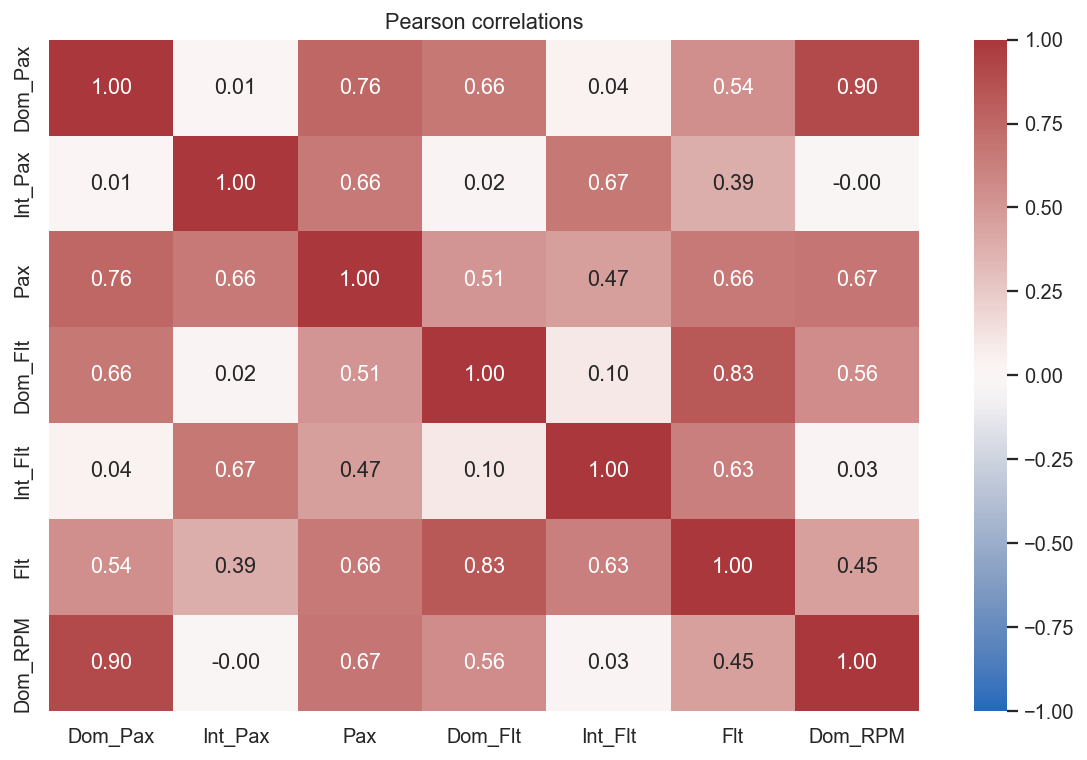

In [4]:
# Step 5. Correlations use available pairs. Exclude diagonal entries and
# mirrored duplicates when ranking relationships by absolute strength.
corr = df.corr()
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Pearson correlations")
fig.tight_layout()
plt.show()

upper = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(upper).stack().sort_values(key=abs, ascending=False)
print("Strongest correlations:")
print(pairs.head(5).round(3).to_string())

## 3. Hypothesis Testing

In [5]:
# Step 6. Test equality of means with the requested independent t-test.
# Welch's version allows different variances. Report the observed mean gap.
alpha = 0.05
dom, intl = df["Dom_Pax"].dropna(), df["Int_Pax"].dropna()
welch = stats.ttest_ind(dom, intl, equal_var=False)
gap = dom.mean() - intl.mean()

def decision(p):
    return "Reject H0" if p < alpha else "Fail to reject H0"

print(f"Welch t = {welch.statistic:.3f}, p = {welch.pvalue:.3g}: {decision(welch.pvalue)}")
print(f"Domestic mean: {dom.mean():,.0f} | International mean: {intl.mean():,.0f}")
print(f"Domestic minus international: {gap:+,.0f} passengers")

# If rows represent matched periods, compare within-row differences as well.
matched = df[["Dom_Pax", "Int_Pax"]].dropna()
paired = stats.ttest_rel(matched["Dom_Pax"], matched["Int_Pax"])
print(f"Paired sensitivity check: t = {paired.statistic:.3f}, p = {paired.pvalue:.3g}")

Welch t = 11.489, p = 1.6e-26: Reject H0
Domestic mean: 175,331 | International mean: 126,924
Domestic minus international: +48,407 passengers
Paired sensitivity check: t = 11.551, p = 5.93e-24


In [6]:
# Step 7. Test whether the population Pearson correlation is zero.
# Both values must come from the same observation.
flight_pairs = df[["Flt", "Pax"]].dropna()
pearson = stats.pearsonr(flight_pairs["Flt"], flight_pairs["Pax"])
print(f"Pearson r = {pearson.statistic:.3f}, p = {pearson.pvalue:.3g}: {decision(pearson.pvalue)}")

Pearson r = 0.659, p = 2.61e-26: Reject H0


The requested Welch test assumes independent groups. The paired check is more appropriate when both passenger counts refer to the same reporting period. Both checks still assume independent observations across rows. If they are successive periods with serial dependence, the usual p-values can be too optimistic. Statistical significance alone does not establish operational importance or causation.

## 4. Simple Linear Regression

In [7]:
# Step 8. Split once so every model uses exactly the same train and test rows.
# Exclude missing targets. Predictor medians are learned inside each pipeline.
train, test = train_test_split(df.dropna(subset=["Pax"]), test_size=0.2, random_state=42)
y_train, y_test = train["Pax"], test["Pax"]

def fit_model(features, scale=False):
    steps = [SimpleImputer(strategy="median")]
    if scale:
        steps.append(StandardScaler())
    model = make_pipeline(*steps, LinearRegression())
    model.fit(train[features], y_train)
    return model, model.predict(test[features])

def metrics(prediction):
    mse = mean_squared_error(y_test, prediction)
    return {"R²": r2_score(y_test, prediction), "MSE": mse,
            "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_test, prediction)}

simple, pred_simple = fit_model(["Flt"])
simple_metrics = metrics(pred_simple)
line = simple.named_steps["linearregression"]
print(f"Pax = {line.intercept_:,.2f} + {line.coef_[0]:.4f} × Flt")
print(pd.Series(simple_metrics).round(4).to_string())

Pax = 37,496.15 + 11.4456 × Flt
R²      2.977000e-01
MSE     2.141722e+09
RMSE    4.627874e+04
MAE     3.660559e+04


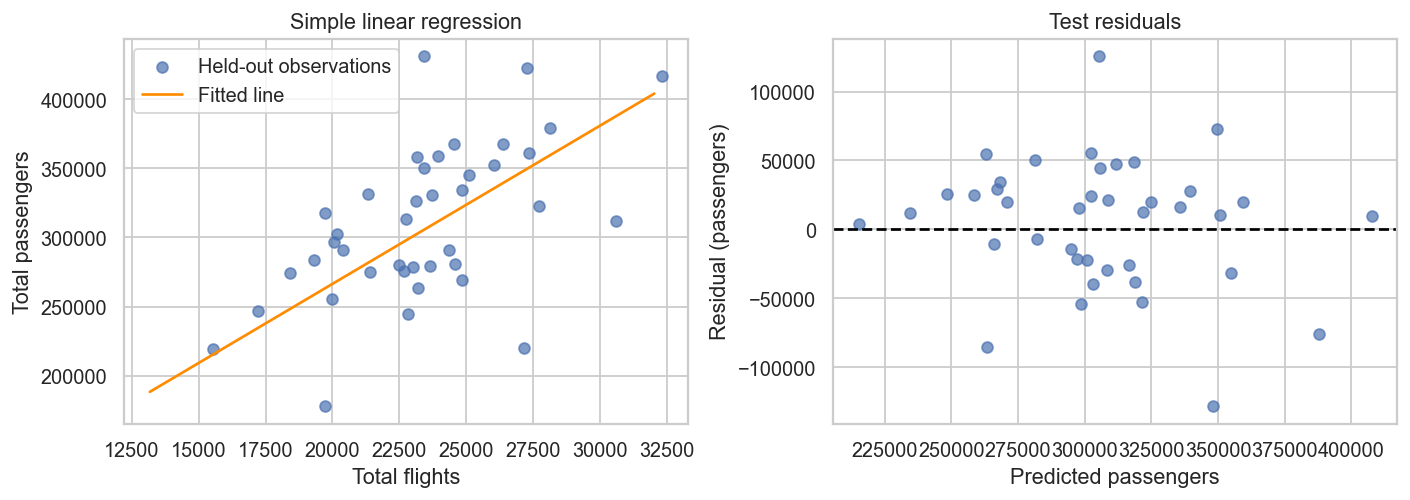

In [8]:
# Step 9. Plot the fitted line against held-out points and examine residuals.
# Residual = actual minus predicted. A positive residual is an underprediction.
def residual_plot(ax, predicted):
    ax.scatter(predicted, y_test.to_numpy() - predicted, alpha=0.7)
    ax.axhline(0, color="black", ls="--")
    ax.set(xlabel="Predicted passengers", ylabel="Residual (passengers)", title="Test residuals")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(test["Flt"], y_test, alpha=0.7, label="Held-out observations")
levels = pd.DataFrame({"Flt": np.linspace(train["Flt"].min(), train["Flt"].max(), 100)})
axes[0].plot(levels["Flt"], simple.predict(levels), color="darkorange", label="Fitted line")
axes[0].set(xlabel="Total flights", ylabel="Total passengers", title="Simple linear regression")
axes[0].legend()
residual_plot(axes[1], pred_simple)
fig.tight_layout()
plt.show()

## 5. Multiple Linear Regression

In [9]:
# Step 10. Fit the course-specified predictors, then a separate flights-only
# model. Keep Flt out of both models because it duplicates the sum of the
# two flight counts. Exclude RPM from the flights-only forecast example
# because realized passenger-miles may be unavailable at prediction time.
requested = ["Dom_Pax", "Int_Pax", "Dom_Flt", "Int_Flt", "Dom_RPM"]
multiple, pred_multiple = fit_model(requested, scale=True)
flights_model, pred_flights = fit_model(["Dom_Flt", "Int_Flt"], scale=True)

# Convert standardized coefficients back to original input units.
reg = multiple.named_steps["linearregression"]
scaler = multiple.named_steps["standardscaler"]
print(pd.DataFrame({"Per 1 SD": reg.coef_, "Per original unit": reg.coef_ / scaler.scale_},
                   index=requested).round(6).to_string())
print(pd.Series(metrics(pred_multiple)).round(4).to_string())

             Per 1 SD  Per original unit
Dom_Pax  45354.288807                1.0
Int_Pax  38979.741046                1.0
Dom_Flt      0.000000                0.0
Int_Flt      0.000000                0.0
Dom_RPM     -0.000000               -0.0
R²      1.0
MSE     0.0
RMSE    0.0
MAE     0.0


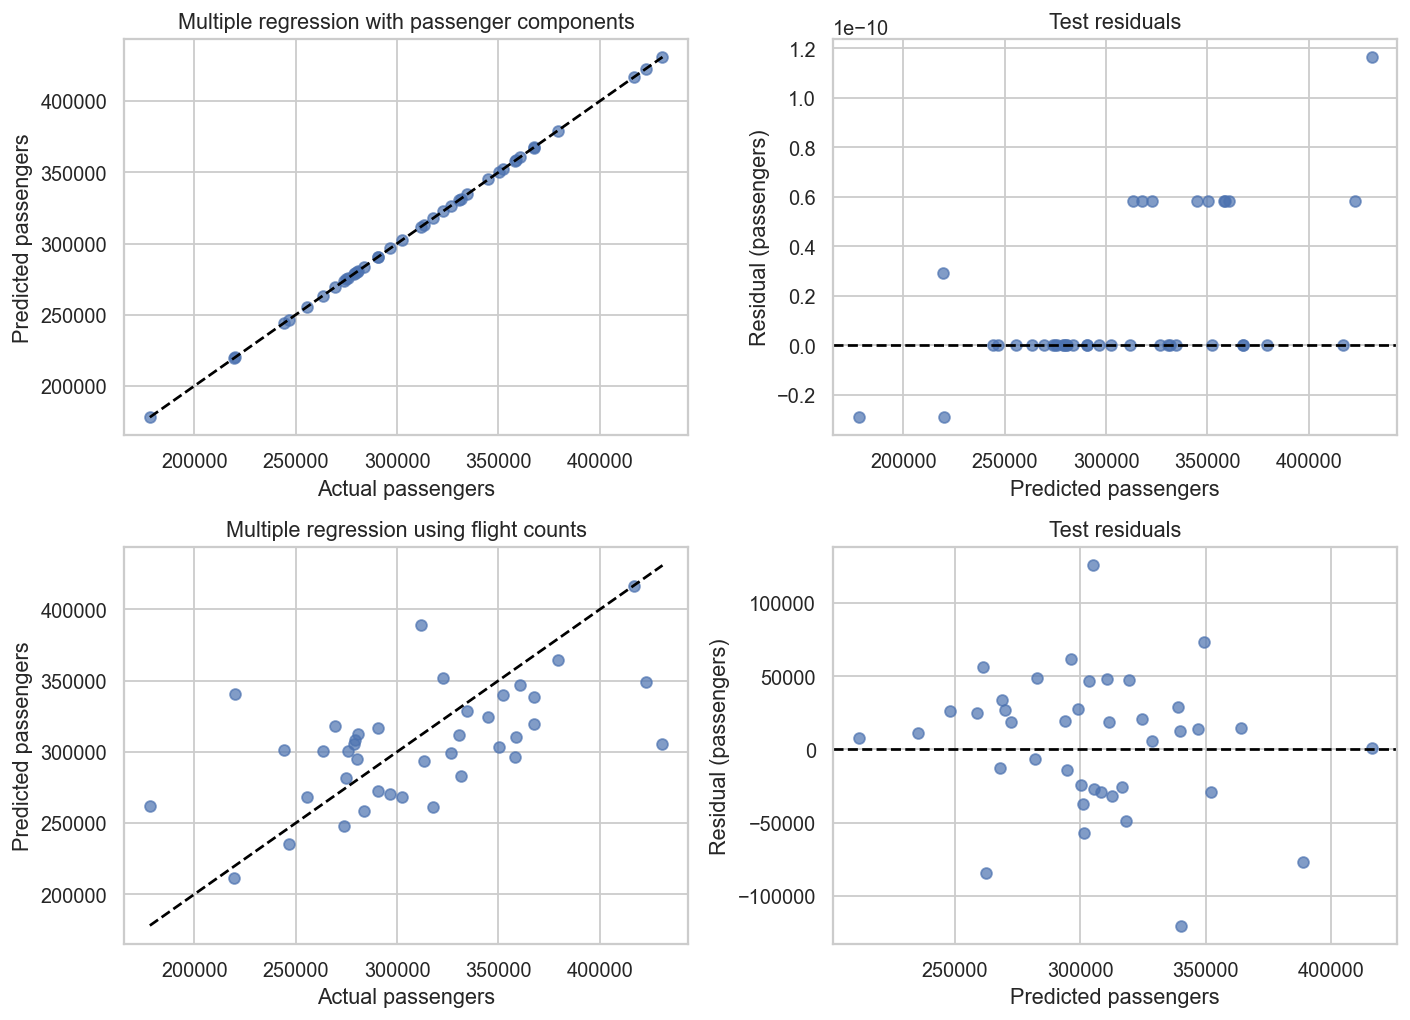

In [10]:
# Step 11. Plot predictions against the identity line, then look for
# structure in the residuals. Compare the target-components fit with the
# flights-only fit to see the effect of removing contemporaneous counts.
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, title, prediction in [
    (0, "Multiple regression with passenger components", pred_multiple),
    (1, "Multiple regression using flight counts", pred_flights),
]:
    low = min(y_test.min(), prediction.min())
    high = max(y_test.max(), prediction.max())
    axes[row, 0].scatter(y_test, prediction, alpha=0.7)
    axes[row, 0].plot([low, high], [low, high], "--", color="black")
    axes[row, 0].set(title=title, xlabel="Actual passengers", ylabel="Predicted passengers")
    residual_plot(axes[row, 1], prediction)
fig.tight_layout()
plt.show()

## 6. Model Comparison and Analysis

In [11]:
# Step 12. Report the same metrics for all models. For errors, a positive
# improvement means a reduction. Use absolute old R² as the denominator
# so a move toward a higher R² retains the positive sign.
table = pd.DataFrame({
    "Simple: total flights": simple_metrics,
    "Multiple: passenger components": metrics(pred_multiple),
    "Multiple: flight counts only": metrics(pred_flights),
}).T
print(table.round(4).to_string())
original = table.iloc[0]
for label in table.index[1:]:
    new = table.loc[label]
    improvements = {
        "R² increase (%)": 100 * (new["R²"] - original["R²"]) / abs(original["R²"]) if original["R²"] else np.nan,
        "RMSE reduction (%)": 100 * (original["RMSE"] - new["RMSE"]) / original["RMSE"] if original["RMSE"] else np.nan,
        "MAE reduction (%)": 100 * (original["MAE"] - new["MAE"]) / original["MAE"] if original["MAE"] else np.nan,
    }
    print(label)
    print(pd.Series(improvements).round(2).to_string())

                                    R²           MSE        RMSE         MAE
Simple: total flights           0.2977  2.141722e+09  46278.7380  36605.5871
Multiple: passenger components  1.0000  0.000000e+00      0.0000      0.0000
Multiple: flight counts only    0.3109  2.101442e+09  45841.4929  36172.1037
Multiple: passenger components
R² increase (%)       235.88
RMSE reduction (%)    100.00
MAE reduction (%)     100.00
Multiple: flight counts only
R² increase (%)       4.44
RMSE reduction (%)    0.94
MAE reduction (%)     1.18


## 7. Statistical Insights and Conclusions

With the starter's synthetic data, domestic traffic averaged **48,407** more passengers per observation than international traffic. The Welch test gave **p = 1.6e-26**. Total flights and passengers had **r = 0.659** (p = 2.61e-26). This positive relationship is expected because the generator uses flight volume to create passenger counts.

The single-predictor model explained **29.8%** of held-out variation. The requested multiple model reached **R² = 1.000** because its inputs include the two counts that define the target. If both counts are available, add them directly. The flights-only extension achieved **R² = 0.311** and an RMSE of **45,841** passengers, compared with **46,279** for the simple model.

For a real planning exercise, use flight schedules known before the forecast, validate on later periods, and compare typical forecast errors with staffing or gate capacity. Check whether domestic and international flight volumes add information separately before deploying the more complex model.

## 8. Reflection Questions

1. **What do the tests reveal?** The generated domestic and international counts differ in mean, and total flight volume is positively associated with total passengers. The tests describe patterns in the observations. A real operational conclusion requires real data and a sampling design that supports inference.
2. **Why did the multiple model fit better?** Its passenger inputs add up to the outcome, so it can reconstruct the answer. The flights-only comparison tests whether separating flight counts adds forecast value without using the answer's components.
3. **How can airlines use the correlation?** Flight counts can serve as an early workload indicator. Teams could forecast demand from published schedules and check error by route, season, and flight mix before using it to plan staffing.
4. **What do residuals show?** Look for curvature, widening scatter, and outliers. Curvature suggests a missed relationship and widening scatter suggests changing error variance. Near-zero residuals in the passenger-components model come from the arithmetic identity. A residual-versus-time plot would help check serial dependence if dates were available.
5. **Where could the models help?** Flights-based estimates can support staffing and capacity scenarios. If the passenger counts are already recorded, calculate the total directly and use the identity to reconcile data.